# ElasticNet Benchmark — RAW vs SCALED (Separate Analyses + Plots)

This notebook runs the full analysis **twice**:

1. **RAW** (original model outputs)
2. **SCALED** (per-sample min–max scaling of `true` and `predicted` separately, scTranslator-style)

It produces four plot files:

- `elasticnet_metrics_raw.png`
- `elasticnet_detailed_metrics_raw.png`
- `elasticnet_metrics_scaled.png`
- `elasticnet_detailed_metrics_scaled.png`

**Input expected:** an HDF5 file named `enet_full_results.h5` in the current working directory (or set `H5_PATH` below).


In [1]:
# 0) Imports
import joblib  # imported in scripts; not required for metrics but kept for parity
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path


In [2]:
# 1) Config
H5_PATH = Path("enet_all_results.h5")  # change if needed

OUT_METRICS_RAW = Path("elasticnet_metrics_raw.png")
OUT_DETAILED_RAW = Path("elasticnet_detailed_metrics_raw.png")

OUT_METRICS_SCALED = Path("elasticnet_metrics_scaled.png")
OUT_DETAILED_SCALED = Path("elasticnet_detailed_metrics_scaled.png")

if not H5_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {H5_PATH.resolve()} — place 'elasticnet_results.h5' next to this notebook or update H5_PATH."
    )


## 2) Load the HDF5 into one long DataFrame (`combined_df`)

Expected columns:
- `protein`
- `LOO sample`
- `true`
- `predicted`


In [3]:
# 2a) Read all protein tables and build a long DataFrame
rows = []

with pd.HDFStore(H5_PATH, mode="r") as store:
    keys = store.keys()
    print(f"Found {len(keys)} protein keys in HDF5")

    for key in keys:
        protein_name = key.strip("/")
        t = store[key].copy()

        # Required columns check (matches what the scripts assume)
        req = {"LOO sample", "true", "predicted"}
        missing = req - set(t.columns)
        if missing:
            raise ValueError(
                f"Key '{key}' is missing required columns: {sorted(missing)}. Found: {list(t.columns)}"
            )

        tmp = t[["LOO sample", "true", "predicted"]].copy()
        tmp["protein"] = protein_name
        rows.append(tmp)

combined_df = pd.concat(rows, ignore_index=True)
combined_df = combined_df[["protein", "LOO sample", "true", "predicted"]]

print("combined_df shape:", combined_df.shape)
combined_df.head()


Found 5113 protein keys in HDF5
combined_df shape: (1886697, 4)


,protein,LOO sample,true,predicted
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651
1,A2M,SH4_SKIN,1.642186,0.308402
2,A2M,AU565_BREAST,-1.129114,-0.899868
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243
4,A2M,CAL51_BREAST,0.274652,0.275565


In [4]:
# 2b) Ensure numeric (coerce non-numeric to NaN)
df = combined_df.copy()
df["true"] = pd.to_numeric(df["true"], errors="coerce")
df["predicted"] = pd.to_numeric(df["predicted"], errors="coerce")

print("NaNs after coercion:")
print("  true     :", int(df["true"].isna().sum()))
print("  predicted:", int(df["predicted"].isna().sum()))


NaNs after coercion:
  true     : 0
  predicted: 0


## 3) Build RAW matrices (samples × proteins)

In [5]:
# 3a) RAW pivot matrices
GT_raw = df.pivot(index="LOO sample", columns="protein", values="true")
PRED_raw = df.pivot(index="LOO sample", columns="protein", values="predicted")

print("RAW shapes:")
print("  GT_raw  :", GT_raw.shape)
print("  PRED_raw:", PRED_raw.shape)

assert list(GT_raw.index) == list(PRED_raw.index), "Sample indices don't match!"
assert list(GT_raw.columns) == list(PRED_raw.columns), "Protein columns don't match!"


RAW shapes:
  GT_raw  : (369, 5113)
  PRED_raw: (369, 5113)


## 4) Build SCALED matrices (per-sample min–max scaling, true/pred separately)

In [6]:
# 4a) Scaling function (scTranslator-style)
EPS = 1e-8  # lower bound in target range

def normalization(x: pd.Series, low: float = EPS, high: float = 1.0) -> pd.Series:
    xmin = x.min(skipna=True)
    xmax = x.max(skipna=True)
    if pd.isna(xmin) or pd.isna(xmax):
        return pd.Series(np.nan, index=x.index, dtype="float64")
    if xmax == xmin:
        return pd.Series(low, index=x.index, dtype="float64")
    return low + (x - xmin) / (xmax - xmin) * (high - low)


In [7]:
# 4b) Apply scaling per sample, separately for true and predicted
df["true_mm"] = df.groupby("LOO sample", observed=True)["true"].transform(normalization)
df["pred_mm"] = df.groupby("LOO sample", observed=True)["predicted"].transform(normalization)

df["true_mm"] = df["true_mm"].clip(lower=EPS, upper=1.0)
df["pred_mm"] = df["pred_mm"].clip(lower=EPS, upper=1.0)

print("Ranges after scaling:")
print("  true_mm :", float(np.nanmin(df["true_mm"])), "→", float(np.nanmax(df["true_mm"])))
print("  pred_mm :", float(np.nanmin(df["pred_mm"])), "→", float(np.nanmax(df["pred_mm"])))


Ranges after scaling:
  true_mm : 1e-08 → 1.0
  pred_mm : 1e-08 → 1.0


In [8]:
# 4c) SCALED pivot matrices
GT_scaled = df.pivot(index="LOO sample", columns="protein", values="true_mm")
PRED_scaled = df.pivot(index="LOO sample", columns="protein", values="pred_mm")

print("SCALED shapes:")
print("  GT_scaled  :", GT_scaled.shape)
print("  PRED_scaled:", PRED_scaled.shape)

assert list(GT_scaled.index) == list(PRED_scaled.index), "Sample indices don't match!"
assert list(GT_scaled.columns) == list(PRED_scaled.columns), "Protein columns don't match!"


SCALED shapes:
  GT_scaled  : (369, 5113)
  PRED_scaled: (369, 5113)


## 5) Metric functions (same as scripts)

In [9]:
def cosine_similarity(y_true, y_pred, eps=1e-8):
    dot_product = np.dot(y_true, y_pred)
    norm_true = np.linalg.norm(y_true)
    norm_pred = np.linalg.norm(y_pred)
    return dot_product / max(norm_true * norm_pred, eps)

def pearson_correlation(y_true, y_pred):
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    return np.corrcoef(y_true, y_pred)[0, 1]

def spearman_correlation(y_true, y_pred):
    return stats.spearmanr(y_true, y_pred)[0]

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


## 6) Helper functions to compute metrics and generate plots

In [10]:
def compute_mean_metrics(ground_truth, predictions):
    metrics_per_sample = {
        "MSE": [],
        "RMSE": [],
        "MAE": [],
        "Pearson": [],
        "Spearman": [],
        "Cosine": [],
    }

    for sample in predictions.index.tolist():
        y_true = ground_truth.loc[sample].values.astype(float)
        y_pred = predictions.loc[sample].values.astype(float)

        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]

        if len(y_true_clean) > 0:
            metrics_per_sample["MSE"].append(mse(y_true_clean, y_pred_clean))
            metrics_per_sample["RMSE"].append(rmse(y_true_clean, y_pred_clean))
            metrics_per_sample["MAE"].append(mae(y_true_clean, y_pred_clean))
            metrics_per_sample["Pearson"].append(pearson_correlation(y_true_clean, y_pred_clean))
            metrics_per_sample["Spearman"].append(spearman_correlation(y_true_clean, y_pred_clean))
            metrics_per_sample["Cosine"].append(cosine_similarity(y_true_clean, y_pred_clean))

    return {k: np.nanmean(v) for k, v in metrics_per_sample.items()}

def compute_detailed_tables(ground_truth, predictions):
    # Per-cell metrics
    per_cell = {"sample": [], "cosine": [], "pearson": [], "mse": [], "mae": []}
    samples = predictions.index.tolist()
    proteins = predictions.columns.tolist()

    for sample in samples:
        y_true = ground_truth.loc[sample].values.astype(float)
        y_pred = predictions.loc[sample].values.astype(float)

        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]

        if len(y_true_clean) > 0:
            per_cell["sample"].append(sample)
            per_cell["cosine"].append(cosine_similarity(y_true_clean, y_pred_clean))
            per_cell["pearson"].append(pearson_correlation(y_true_clean, y_pred_clean))
            per_cell["mse"].append(mse(y_true_clean, y_pred_clean))
            per_cell["mae"].append(mae(y_true_clean, y_pred_clean))

    per_cell_df = pd.DataFrame(per_cell)

    # Per-protein PCC across samples
    per_protein = {"protein": [], "pearson": []}
    for protein in proteins:
        y_true = ground_truth[protein].values.astype(float)
        y_pred = predictions[protein].values.astype(float)

        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]

        if len(y_true_clean) > 1:
            per_protein["protein"].append(protein)
            per_protein["pearson"].append(pearson_correlation(y_true_clean, y_pred_clean))

    per_protein_df = pd.DataFrame(per_protein).sort_values("pearson", ascending=False)
    top_10 = per_protein_df.head(10)
    bottom_10 = per_protein_df.tail(10)

    return per_cell_df, per_protein_df, top_10, bottom_10

def plot_overall_bar(mean_metrics, title, out_path):
    plt.style.use("seaborn-v0_8-whitegrid")

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    fig.patch.set_facecolor("#F8F9FA")

    fig.suptitle(title, fontsize=20, fontweight="bold", color="#2C3E50", y=0.98)

    colors = ["#E74C3C", "#E67E22", "#F39C12", "#27AE60", "#2980B9", "#9B59B6"]
    plots = [
        ("Mean Squared Error", "MSE", mean_metrics["MSE"], colors[0]),
        ("Root MSE", "RMSE", mean_metrics["RMSE"], colors[1]),
        ("Mean Absolute Error", "MAE", mean_metrics["MAE"], colors[2]),
        ("Pearson Correlation", "PCC", mean_metrics["Pearson"], colors[3]),
        ("Spearman Correlation", "SCC", mean_metrics["Spearman"], colors[4]),
        ("Cosine Similarity", "COS", mean_metrics["Cosine"], colors[5]),
    ]

    for idx, (t, ylabel, value, color) in enumerate(plots):
        row, col = divmod(idx, 3)
        ax = axes[row, col]
        ax.set_facecolor("#FFFFFF")

        bar = ax.bar(["ElasticNet"], [value], color=color, width=0.6,
                     edgecolor="#2C3E50", linewidth=2, alpha=0.9)

        ax.bar(["ElasticNet"], [value], color="gray", width=0.6, alpha=0.1,
               bottom=-value * 0.02 if value > 0 else value * 0.02)

        for rect in bar:
            height = rect.get_height()
            ax.annotate(
                f"{value:.4f}",
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=14,
                fontweight="bold",
                color="#2C3E50",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=color, alpha=0.8),
            )

        ax.set_title(t, fontsize=14, fontweight="bold", color="#2C3E50", pad=15)
        ax.set_ylabel(ylabel, fontsize=12, fontweight="bold", color="#2C3E50")

        if value >= 0:
            ax.set_ylim(0, value * 1.35 if value > 0 else 1)
        else:
            ax.set_ylim(value * 1.35, abs(value) * 0.35)

        ax.tick_params(axis="x", labelsize=12, colors="#2C3E50")
        ax.tick_params(axis="y", labelsize=10, colors="#7F8C8D")
        ax.yaxis.grid(True, linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_color("#BDC3C7")
            spine.set_linewidth(1.5)
        ax.spines["bottom"].set_visible(False)

    plt.tight_layout(rect=[0, 0.02, 1, 0.95])
    plt.savefig(out_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved: {out_path}")
    plt.show()

def plot_detailed(per_cell_df, per_protein_df, top_10, bottom_10, title, out_path):
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(
        2, 3,
        width_ratios=[1, 1, 1],
        height_ratios=[1, 1],
        hspace=0.3,
        wspace=0.3,
    )

    cell_cosine_color = "#5DADE2"
    cell_pcc_color = "#F5B041"
    cell_mse_color = "#58D68D"
    protein_pcc_color = "#AF7AC5"

    # 1) Per-cell cosine
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.hist(per_cell_df["cosine"], bins=30, color=cell_cosine_color, edgecolor="black", alpha=0.8)
    mean_cosine = per_cell_df["cosine"].mean()
    ax1.axvline(mean_cosine, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_cosine:.3f}")
    ax1.set_xlabel("Cosine Similarity", fontsize=10)
    ax1.set_ylabel("Count", fontsize=10)
    ax1.set_title("Per-Cell Cosine Similarity", fontsize=12, fontweight="bold")
    ax1.legend(loc="upper right")

    # 2) Per-cell PCC
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.hist(per_cell_df["pearson"], bins=30, color=cell_pcc_color, edgecolor="black", alpha=0.8)
    mean_pcc = per_cell_df["pearson"].mean()
    ax2.axvline(mean_pcc, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_pcc:.3f}")
    ax2.set_xlabel("Pearson Correlation", fontsize=10)
    ax2.set_ylabel("Count", fontsize=10)
    ax2.set_title("Per-Cell PCC", fontsize=12, fontweight="bold")
    ax2.legend(loc="upper right")

    # 3) Per-cell MSE
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.hist(per_cell_df["mse"], bins=30, color=cell_mse_color, edgecolor="black", alpha=0.8)
    mean_mse = per_cell_df["mse"].mean()
    ax3.axvline(mean_mse, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_mse:.4f}")
    ax3.set_xlabel("MSE", fontsize=10)
    ax3.set_ylabel("Count", fontsize=10)
    ax3.set_title("Per-Cell MSE", fontsize=12, fontweight="bold")
    ax3.legend(loc="upper right")

    # 4) Per-protein PCC
    ax4 = fig.add_subplot(gs[1, 0])
    ax4.hist(per_protein_df["pearson"].dropna(), bins=30, color=protein_pcc_color, edgecolor="black", alpha=0.8)
    mean_protein_pcc = per_protein_df["pearson"].mean()
    ax4.axvline(mean_protein_pcc, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_protein_pcc:.3f}")
    ax4.set_xlabel("Pearson Correlation", fontsize=10)
    ax4.set_ylabel("Count", fontsize=10)
    ax4.set_title("Per-Protein PCC (across cells)", fontsize=12, fontweight="bold")
    ax4.legend(loc="upper right")

    # 5) Top/bottom proteins
    ax5 = fig.add_subplot(gs[1, 1])
    top_10_sorted = top_10.sort_values("pearson", ascending=True)
    bottom_10_sorted = bottom_10.sort_values("pearson", ascending=False)
    combined = pd.concat([top_10_sorted, bottom_10_sorted])

    colors = ["#58D68D"] * 10 + ["#E74C3C"] * 10
    y_pos = np.arange(len(combined))
    ax5.barh(y_pos, combined["pearson"].values, color=colors, edgecolor="black", alpha=0.8)
    ax5.set_yticks(y_pos)
    ax5.set_yticklabels(combined["protein"].values, fontsize=8)
    ax5.axvline(0, color="red", linestyle="-", linewidth=1)
    ax5.set_xlabel("PCC", fontsize=10)
    ax5.set_title("Top 10 / Bottom 10 Proteins by PCC", fontsize=12, fontweight="bold")

    # 6) Summary panel
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.axis("off")

    n_cells = len(per_cell_df)
    n_proteins = len(per_protein_df)
    positive_pcc_count = (per_protein_df["pearson"] > 0).sum()
    positive_pcc_pct = positive_pcc_count / n_proteins * 100 if n_proteins else np.nan
    high_pcc_03 = (per_protein_df["pearson"] > 0.3).sum()
    high_pcc_05 = (per_protein_df["pearson"] > 0.5).sum()

    summary_text = f"""Summary Statistics
{'='*40}

Per-Cell (n={n_cells}):
Cosine:
  Mean: {per_cell_df['cosine'].mean():.4f} +/- {per_cell_df['cosine'].std():.4f}
  Min:  {per_cell_df['cosine'].min():.4f}
  Max:  {per_cell_df['cosine'].max():.4f}

Pearson:
  Mean: {per_cell_df['pearson'].mean():.4f} +/- {per_cell_df['pearson'].std():.4f}
  Min:  {per_cell_df['pearson'].min():.4f}
  Max:  {per_cell_df['pearson'].max():.4f}

MSE:
  Mean: {per_cell_df['mse'].mean():.4f} +/- {per_cell_df['mse'].std():.4f}

MAE:
  Mean: {per_cell_df['mae'].mean():.4f} +/- {per_cell_df['mae'].std():.4f}

Per-Protein PCC (n={n_proteins}):
  Mean: {per_protein_df['pearson'].mean():.4f} +/- {per_protein_df['pearson'].std():.4f}
  Positive: {positive_pcc_count} ({positive_pcc_pct:.1f}%)
  > 0.3:    {high_pcc_03} ({(high_pcc_03/n_proteins*100) if n_proteins else np.nan:.1f}%)
  > 0.5:    {high_pcc_05} ({(high_pcc_05/n_proteins*100) if n_proteins else np.nan:.1f}%)
"""

    ax6.text(
        0.05, 0.95,
        summary_text,
        transform=ax6.transAxes,
        fontsize=9,
        verticalalignment="top",
        fontfamily="monospace",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    )

    fig.suptitle(title, fontsize=16, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.show()


# RAW analysis (original scale)

In [11]:
# 7) RAW: compute mean metrics
mean_metrics_raw = compute_mean_metrics(GT_raw, PRED_raw)
print("Mean Metrics (RAW):")
for k, v in mean_metrics_raw.items():
    print(f"  {k:8s}: {v:.6f}")


Mean Metrics (RAW):
  MSE     : 0.349150
  RMSE    : 0.579322
  MAE     : 0.444333
  Pearson : 0.668077
  Spearman: 0.569050
  Cosine  : 0.656606


Saved: elasticnet_metrics_raw.png


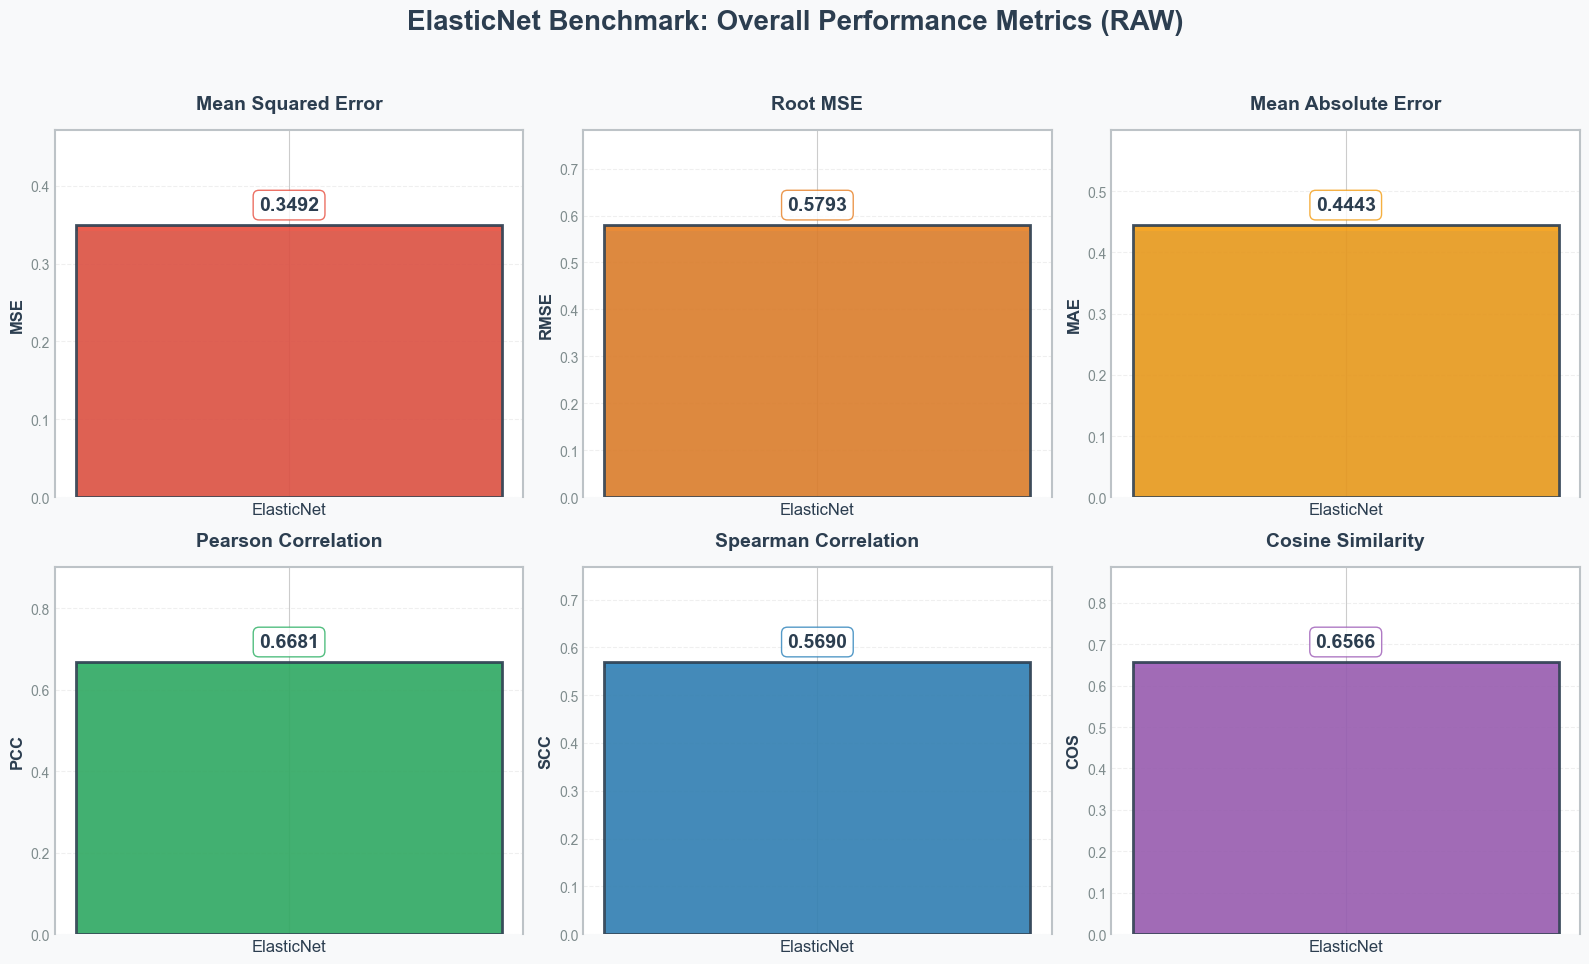

In [12]:
# 8) RAW: overall bar chart
plot_overall_bar(
    mean_metrics_raw,
    title="ElasticNet Benchmark: Overall Performance Metrics (RAW)",
    out_path=OUT_METRICS_RAW
)


In [13]:
# 9) RAW: detailed tables
per_cell_raw, per_protein_raw, top10_raw, bottom10_raw = compute_detailed_tables(GT_raw, PRED_raw)

print("RAW detailed tables:")
print("  cells   :", len(per_cell_raw))
print("  proteins:", len(per_protein_raw))

display(per_cell_raw.head())
display(per_protein_raw.head(10))


RAW detailed tables:
  cells   : 369
  proteins: 5113


,sample,cosine,pearson,mse,mae
0,22RV1_PROSTATE,0.638976,0.636914,0.496394,0.569589
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.802465,0.797503,0.342388,0.453077
2,769P_KIDNEY,0.743420,0.769340,0.271616,0.382869
3,786O_KIDNEY,0.655691,0.652421,0.350048,0.472970
4,8305C_THYROID,0.619457,0.628299,0.464801,0.541696


,protein,pearson
2016,IGF2BP1,0.908862
433,BASP1,0.906439
2346,MAGEA4,0.898980
2363,MAP1B,0.885239
1719,GNG12,0.885098
924,CORO1A,0.884077
4526,TJP2,0.879913
2233,LCP1,0.879216
1843,HCLS1,0.878749
3655,RBM47,0.877860


C:\Users\hp\AppData\Local\Temp\ipykernel_38056\773615424.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: elasticnet_detailed_metrics_raw.png


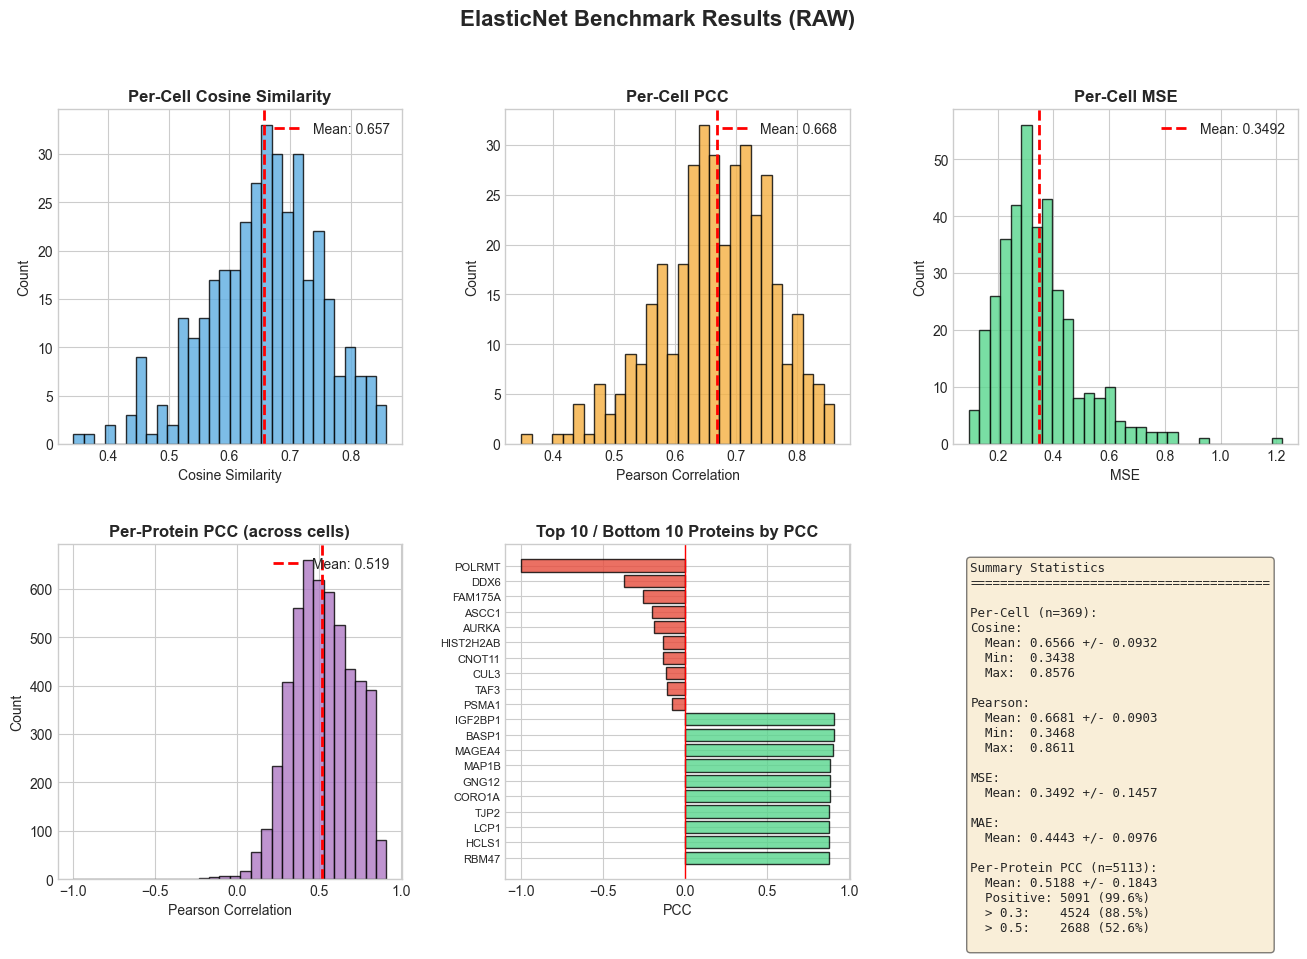

In [14]:
# 10) RAW: detailed visualization
plot_detailed(
    per_cell_raw,
    per_protein_raw,
    top10_raw,
    bottom10_raw,
    title="ElasticNet Benchmark Results (RAW)",
    out_path=OUT_DETAILED_RAW
)


# SCALED analysis (per-sample min–max)

In [15]:
# 11) SCALED: compute mean metrics
mean_metrics_scaled = compute_mean_metrics(GT_scaled, PRED_scaled)
print("Mean Metrics (SCALED per-sample min–max):")
for k, v in mean_metrics_scaled.items():
    print(f"  {k:8s}: {v:.6f}")


Mean Metrics (SCALED per-sample min–max):
  MSE     : 0.016814
  RMSE    : 0.115082
  MAE     : 0.100603
  Pearson : 0.668077
  Spearman: 0.569050
  Cosine  : 0.988667


Saved: elasticnet_metrics_scaled.png


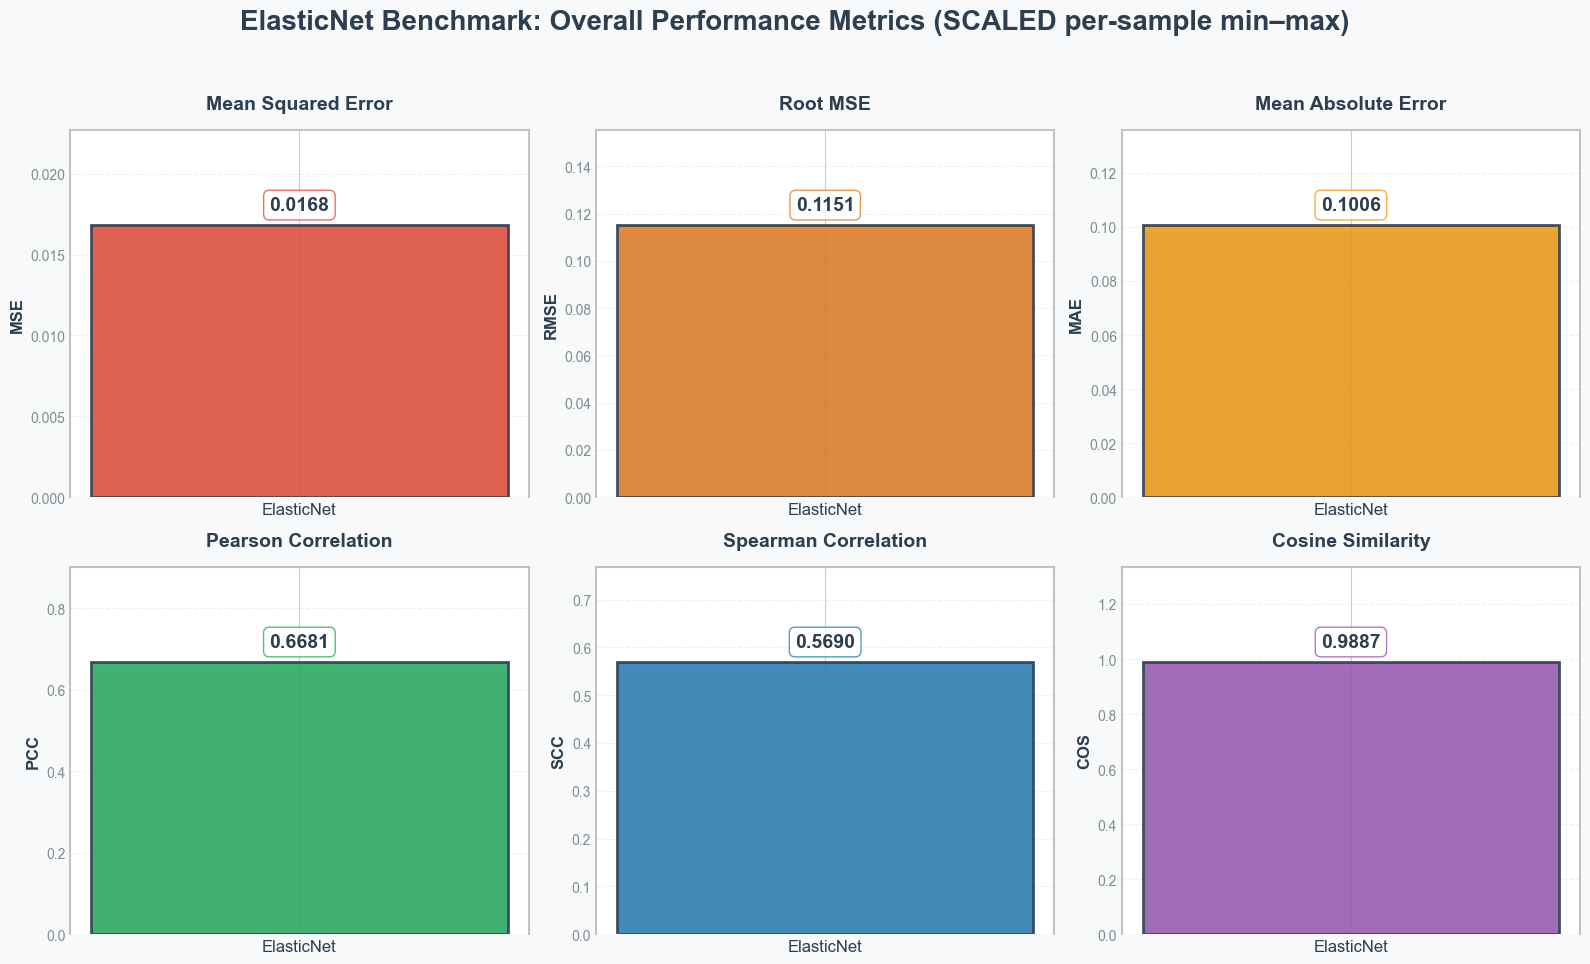

In [16]:
# 12) SCALED: overall bar chart
plot_overall_bar(
    mean_metrics_scaled,
    title="ElasticNet Benchmark: Overall Performance Metrics (SCALED per-sample min–max)",
    out_path=OUT_METRICS_SCALED
)


In [17]:
# 13) SCALED: detailed tables
per_cell_scaled, per_protein_scaled, top10_scaled, bottom10_scaled = compute_detailed_tables(GT_scaled, PRED_scaled)

print("SCALED detailed tables:")
print("  cells   :", len(per_cell_scaled))
print("  proteins:", len(per_protein_scaled))

display(per_cell_scaled.head())
display(per_protein_scaled.head(10))


SCALED detailed tables:
  cells   : 369
  proteins: 5113


,sample,cosine,pearson,mse,mae
0,22RV1_PROSTATE,0.990179,0.636914,0.006625,0.065014
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.988982,0.797503,0.006213,0.064663
2,769P_KIDNEY,0.990764,0.769340,0.007117,0.070091
3,786O_KIDNEY,0.986676,0.652421,0.010046,0.082553
4,8305C_THYROID,0.984207,0.628299,0.006866,0.065935


,protein,pearson
433,BASP1,0.853678
1386,EPCAM,0.805745
3898,S100A14,0.793624
2346,MAGEA4,0.791338
4402,TACSTD2,0.789501
4306,ST14,0.775901
565,CA2,0.774254
4004,SERPINB5,0.774187
3100,PDLIM4,0.773463
2016,IGF2BP1,0.772038


C:\Users\hp\AppData\Local\Temp\ipykernel_38056\773615424.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: elasticnet_detailed_metrics_scaled.png


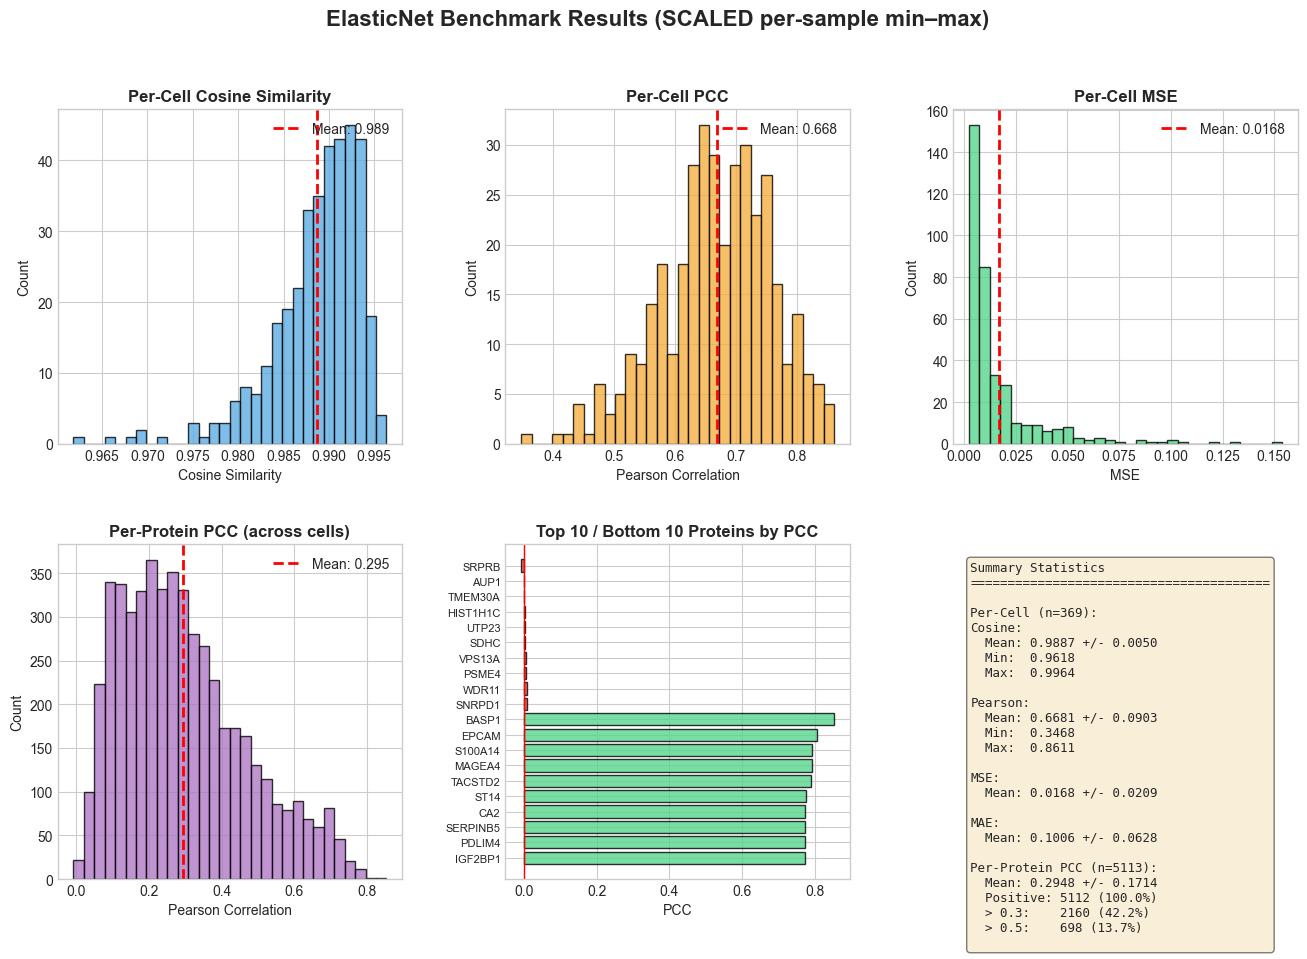

In [18]:
# 14) SCALED: detailed visualization
plot_detailed(
    per_cell_scaled,
    per_protein_scaled,
    top10_scaled,
    bottom10_scaled,
    title="ElasticNet Benchmark Results (SCALED per-sample min–max)",
    out_path=OUT_DETAILED_SCALED
)


## Optional quick check: correlations should match (almost) exactly

Pearson/Spearman are scale-invariant (with positive scaling), so RAW vs SCALED should match except for constant-vector/NaN edge cases.


In [19]:
print("Mean Pearson RAW   :", float(mean_metrics_raw["Pearson"]))
print("Mean Pearson SCALED:", float(mean_metrics_scaled["Pearson"]))
print("Mean Spearman RAW  :", float(mean_metrics_raw["Spearman"]))
print("Mean Spearman SCALED:", float(mean_metrics_scaled["Spearman"]))


Mean Pearson RAW   : 0.6680773220567542
Mean Pearson SCALED: 0.6680773220567542
Mean Spearman RAW  : 0.5690496986218593
Mean Spearman SCALED: 0.5690496986218593
